# Generating names character by character

In [1]:
import torch
import torch.nn as nn

# Vocabulary
chars = list("abcdefghijklmnopqrstuvwxyz")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

# Example name
name = "denish"

# Convert characters to numbers
x = torch.tensor([stoi[ch] for ch in name[:-1]])
y = torch.tensor([stoi[ch] for ch in name[1:]])

print("Input numbers:", x)
print("Target numbers:", y)

# Convert numbers back to characters
input_chars = "".join(itos[i.item()] for i in x)
target_chars = "".join(itos[i.item()] for i in y)

print("Input characters:", input_chars)
print("Target characters:", target_chars)

Input numbers: tensor([ 3,  4, 13,  8, 18])
Target numbers: tensor([ 4, 13,  8, 18,  7])
Input characters: denis
Target characters: enish


In [2]:
class CharModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=16):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.fc = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        x = self.embedding(x)
        x = self.fc(x)
        return x


model = CharModel(len(chars))

logits = model(x)

print(logits.shape)

probabilities = torch.softmax(logits, dim=-1)

torch.Size([5, 26])


# Bigram Neural Network

In [3]:
class BigramModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, vocab_size)

    def forward(self, x):
        return self.embedding(x)


model = BigramModel(len(chars))

logits = model(x)

print(logits.shape)

## Training

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

for epoch in range(1000):

    logits = model(x)

    loss = loss_fn(logits, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(epoch, loss.item())

torch.Size([5, 26])
0 4.292569160461426
200 1.0636682510375977
400 0.22024360299110413
600 0.09123680740594864
800 0.051632970571517944


# Generating Our Training Data

In [4]:
import torch

names = [
    "alex",
    "alice",
    "bob",
    "david"
]

# Create vocabulary
chars = sorted(set("".join(names)))
chars = ["<START>", "<END>"] + chars

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

print("Vocabulary:", chars)

## generate training data

X = []
Y = []

for name in names:

    sequence = ["<START>"] + list(name) + ["<END>"]

    for i in range(len(sequence) - 1):

        input_char = sequence[i]
        target_char = sequence[i + 1]

        X.append(stoi[input_char])
        Y.append(stoi[target_char])

X = torch.tensor(X)
Y = torch.tensor(Y)

print("X:", X)
print("Y:", Y)

batch_size = 4

X_batch = X[:batch_size]
Y_batch = Y[:batch_size]

print(X_batch)
print(Y_batch)

Vocabulary: ['<START>', '<END>', 'a', 'b', 'c', 'd', 'e', 'i', 'l', 'o', 'v', 'x']
X: tensor([ 0,  2,  8,  6, 11,  0,  2,  8,  7,  4,  6,  0,  3,  9,  3,  0,  5,  2,
        10,  7,  5])
Y: tensor([ 2,  8,  6, 11,  1,  2,  8,  7,  4,  6,  1,  3,  9,  3,  1,  5,  2, 10,
         7,  5,  1])
tensor([0, 2, 8, 6])
tensor([ 2,  8,  6, 11])


#  Embeddings and linear layers

Vocabulary size: 26
Token IDs:
tensor([ 7,  4, 11, 11, 14, 22, 14, 17, 11,  3])
X: tensor([ 7,  4, 11, 11, 14, 22, 14, 17, 11])
Y: tensor([ 4, 11, 11, 14, 22, 14, 17, 11,  3])
CharacterModel(
  (embedding): Embedding(26, 8)
  (linear): Linear(in_features=8, out_features=26, bias=True)
)
Epoch 0, Loss: 3.5208
Epoch 200, Loss: 0.5281
Epoch 400, Loss: 0.5224
Epoch 600, Loss: 0.5212
Epoch 800, Loss: 0.5208

Embedding shape:
torch.Size([26, 8])


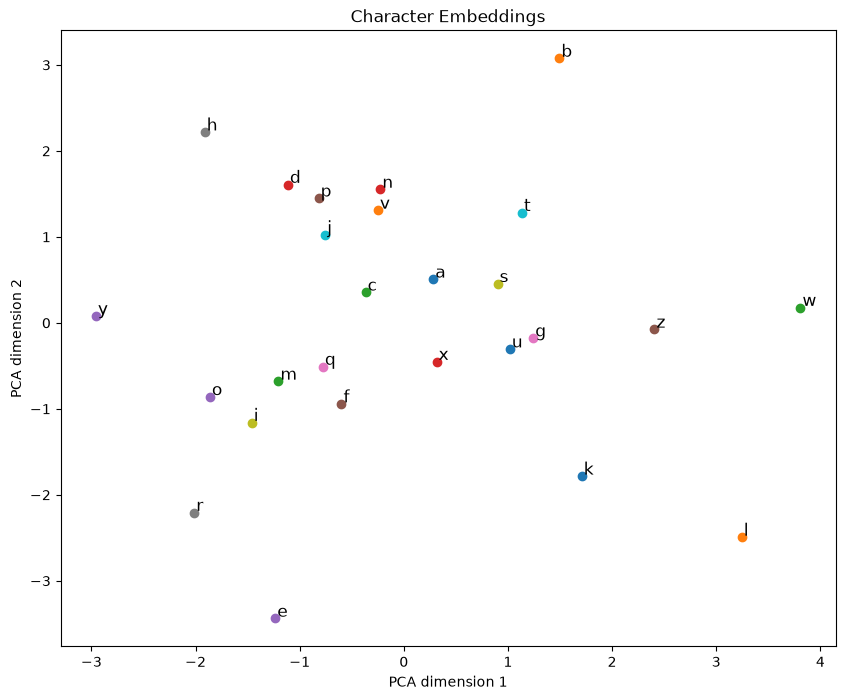

In [7]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================
# 1. Create a small vocabulary
# ==========================================

chars = list("abcdefghijklmnopqrstuvwxyz")

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

vocab_size = len(chars)

print("Vocabulary size:", vocab_size)


# ==========================================
# 2. Example training data
# ==========================================

text = "hello world"

# Convert characters to IDs
ids = torch.tensor([
    stoi[ch]
    for ch in text
    if ch in stoi
])

print("Token IDs:")
print(ids)


# Input = current character
# Target = next character

X = ids[:-1]
Y = ids[1:]

print("X:", X)
print("Y:", Y)


# ==========================================
# 3. Create model
# ==========================================

class CharacterModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim):
        super().__init__()

        # Token ID -> embedding vector
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Embedding vector -> vocabulary scores
        self.linear = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, x):

        # Convert IDs into vectors
        x = self.embedding(x)

        # Predict next character
        x = self.linear(x)

        return x


# ==========================================
# 4. Create model
# ==========================================

embedding_dim = 8

model = CharacterModel(
    vocab_size,
    embedding_dim
)

print(model)


# ==========================================
# 5. Loss and optimizer
# ==========================================

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)


# ==========================================
# 6. Training
# ==========================================

for epoch in range(1000):

    # Forward pass
    logits = model(X)

    # Calculate loss
    loss = loss_fn(logits, Y)

    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch}, Loss: {loss.item():.4f}"
        )


# ==========================================
# 7. Look at embeddings
# ==========================================

embeddings = model.embedding.weight.detach()

print("\nEmbedding shape:")
print(embeddings.shape)

# ==========================================
# 8. Visualize the Embeddings
# ==========================================

# Convert embeddings to NumPy
embedding_numpy = embeddings.numpy()

# Reduce 8D → 2D
pca = PCA(n_components=2)

embedding_2d = pca.fit_transform(
    embedding_numpy
)

# Plot
plt.figure(figsize=(10, 8))

for i, char in enumerate(chars):

    x = embedding_2d[i, 0]
    y = embedding_2d[i, 1]

    plt.scatter(x, y)

    plt.text(
        x + 0.02,
        y + 0.02,
        char,
        fontsize=12
    )

plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.title("Character Embeddings")

plt.show()

# Scaled dot product causal self-attention

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):

    def __init__(self, embed_dim):

        super().__init__()

        self.embed_dim = embed_dim

        # Learnable projections
        self.W_Q = nn.Linear(embed_dim,embed_dim)

        self.W_K = nn.Linear(embed_dim,embed_dim)

        self.W_V = nn.Linear(embed_dim,embed_dim)

        # Final projection
        self.out_proj = nn.Linear(embed_dim,embed_dim)


    def forward(self, x):

        # x:
        # [batch, sequence_length, embedding_dimension]

        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)

        # Attention scores
        scores = Q @ K.transpose(-2, -1)

        # Scale
        d_k = K.size(-1)

        scores = scores / (d_k ** 0.5)

        # Causal mask
        seq_len = x.size(1)

        mask = torch.tril(torch.ones(seq_len,seq_len,device=x.device))

        # Prevent looking at future tokens
        scores = scores.masked_fill(mask == 0,float("-inf"))

        # Attention probabilities
        weights = F.softmax(scores,dim=-1)

        # Weighted values
        output = weights @ V

        # Final linear projection
        output = self.out_proj(output)

        return output

x = torch.randn(
    2,
    5,
    8
)

attention = CausalSelfAttention(
    embed_dim=8
)

output = attention(x)

print("Input shape :", x.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([2, 5, 8])
Output shape: torch.Size([2, 5, 8])


# Transformers -> The decoder

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# =====================================================
# 1. CAUSAL SELF-ATTENTION
# =====================================================

class CausalSelfAttention(nn.Module):

    def __init__(self, embed_dim):
        super().__init__()

        self.q = nn.Linear(embed_dim, embed_dim)
        self.k = nn.Linear(embed_dim, embed_dim)
        self.v = nn.Linear(embed_dim, embed_dim)

        self.out = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):

        Q = self.q(x)
        K = self.k(x)
        V = self.v(x)

        # Attention scores
        scores = Q @ K.transpose(-2, -1)

        # Scale
        d = K.size(-1)
        scores = scores / (d ** 0.5)

        # Causal mask
        seq_len = x.size(1)

        mask = torch.tril(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device
            )
        )

        scores = scores.masked_fill(
            mask == 0,
            float("-inf")
        )

        # Softmax
        weights = F.softmax(
            scores,
            dim=-1
        )

        # Weighted values
        output = weights @ V

        return self.out(output)


# =====================================================
# 2. DECODER BLOCK
# =====================================================

class DecoderBlock(nn.Module):

    def __init__(self, embed_dim, hidden_dim):

        super().__init__()

        self.attention = CausalSelfAttention(
            embed_dim
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.ffn = nn.Sequential(

            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Linear(
                hidden_dim,
                embed_dim
            )
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

    def forward(self, x):

        # Attention + residual
        x = x + self.attention(
            self.norm1(x)
        )

        # Feed-forward + residual
        x = x + self.ffn(
            self.norm2(x)
        )

        return x


# =====================================================
# 3. TRANSFORMER DECODER
# =====================================================

class TransformerDecoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        embed_dim=32,
        hidden_dim=64,
        num_layers=2
    ):

        super().__init__()

        # Token embedding
        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        # Positional embedding
        self.position_embedding = nn.Embedding(
            max_seq_len,
            embed_dim
        )

        # Decoder blocks
        self.blocks = nn.ModuleList([

            DecoderBlock(
                embed_dim,
                hidden_dim
            )

            for _ in range(num_layers)

        ])

        # Final normalization
        self.norm = nn.LayerNorm(
            embed_dim
        )

        # Output layer
        self.output = nn.Linear(
            embed_dim,
            vocab_size
        )

    def forward(self, x):

        # x shape:
        # [batch, sequence_length]

        batch_size, seq_len = x.shape

        # Token embeddings
        token_emb = self.token_embedding(x)

        # Position IDs
        positions = torch.arange(
            seq_len,
            device=x.device
        )

        # Position embeddings
        pos_emb = self.position_embedding(
            positions
        )

        # Combine token + position
        x = token_emb + pos_emb

        # Decoder blocks
        for block in self.blocks:
            x = block(x)

        # Final normalization
        x = self.norm(x)

        # Vocabulary logits
        logits = self.output(x)

        return logits


# =====================================================
# 4. CREATE MODEL
# =====================================================

vocab_size = 30
max_seq_len = 10

model = TransformerDecoder(
    vocab_size=vocab_size,
    max_seq_len=max_seq_len,
    embed_dim=32,
    hidden_dim=64,
    num_layers=2
)


# =====================================================
# 5. CREATE INPUT DATA
# =====================================================

batch_size = 2

x = torch.randint(
    0,
    vocab_size,
    (batch_size, max_seq_len)
)

print("Input:")
print(x)

print("\nInput shape:")
print(x.shape)


# =====================================================
# 6. CREATE TARGETS
# =====================================================

# Target is the NEXT token.
#
# Example:
#
# x:       5  8  2  9
# target:  8  2  9  ...
#
# For this random demonstration,
# create another random target tensor.

targets = torch.randint(
    0,
    vocab_size,
    (batch_size, max_seq_len)
)

print("\nTargets:")
print(targets)

print("\nTarget shape:")
print(targets.shape)


# =====================================================
# 7. FORWARD PASS
# =====================================================

logits = model(x)

print("\nOutput shape:")
print(logits.shape)


# =====================================================
# 8. LOSS FUNCTION
# =====================================================

loss_fn = nn.CrossEntropyLoss()

loss = loss_fn(
    logits.reshape(-1, vocab_size),
    targets.reshape(-1)
)

print("\nLoss:")
print(loss.item())


# =====================================================
# 9. OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)


# =====================================================
# 10. BACKPROPAGATION
# =====================================================

optimizer.zero_grad()

loss.backward()

optimizer.step()

print("\nTraining step completed successfully!")

Input:
tensor([[16, 23, 26, 26, 14, 22, 19, 14,  5, 21],
        [14, 17, 19,  6,  8, 28,  8,  1,  6, 15]])

Input shape:
torch.Size([2, 10])

Targets:
tensor([[ 2, 11, 14, 21, 11, 16, 14,  1, 27,  0],
        [27,  5, 27, 15, 28,  8, 11, 23,  9, 18]])

Target shape:
torch.Size([2, 10])

Output shape:
torch.Size([2, 10, 30])

Loss:
3.3331546783447266

Training step completed successfully!


# Encoder

In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# =====================================================
# 1. ENCODER SELF-ATTENTION
# =====================================================

class SelfAttention(nn.Module):

    def __init__(self, embed_dim):

        super().__init__()

        self.q = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.k = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.v = nn.Linear(
            embed_dim,
            embed_dim
        )

        self.out = nn.Linear(
            embed_dim,
            embed_dim
        )


    def forward(self, x):

        Q = self.q(x)
        K = self.k(x)
        V = self.v(x)

        # Attention scores
        scores = Q @ K.transpose(-2, -1)

        # Scale
        d_k = K.size(-1)

        scores = scores / (d_k ** 0.5)

        # NO CAUSAL MASK
        weights = F.softmax(
            scores,
            dim=-1
        )

        # Weighted values
        output = weights @ V

        return self.out(output)


# =====================================================
# 2. ENCODER BLOCK
# =====================================================

class EncoderBlock(nn.Module):

    def __init__(
        self,
        embed_dim,
        hidden_dim
    ):

        super().__init__()

        self.attention = SelfAttention(
            embed_dim
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.ffn = nn.Sequential(

            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Linear(
                hidden_dim,
                embed_dim
            )
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )


    def forward(self, x):

        # Self-attention + residual
        x = x + self.attention(
            self.norm1(x)
        )

        # Feed-forward + residual
        x = x + self.ffn(
            self.norm2(x)
        )

        return x


# =====================================================
# 3. COMPLETE ENCODER
# =====================================================

class TransformerEncoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        embed_dim=32,
        hidden_dim=64,
        num_layers=2
    ):

        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.position_embedding = nn.Embedding(
            max_seq_len,
            embed_dim
        )

        self.blocks = nn.ModuleList([

            EncoderBlock(
                embed_dim,
                hidden_dim
            )

            for _ in range(num_layers)

        ])

        self.norm = nn.LayerNorm(
            embed_dim
        )


    def forward(self, x):

        batch_size, seq_len = x.shape

        # Token embeddings
        token_emb = self.token_embedding(x)

        # Position IDs
        positions = torch.arange(
            seq_len,
            device=x.device
        )

        # Position embeddings
        pos_emb = self.position_embedding(
            positions
        )

        # Combine
        x = token_emb + pos_emb

        # Encoder blocks
        for block in self.blocks:

            x = block(x)

        # Final normalization
        return self.norm(x)


# =====================================================
# 4. TEST ENCODER
# =====================================================

vocab_size = 100
max_seq_len = 20

encoder = TransformerEncoder(
    vocab_size=vocab_size,
    max_seq_len=max_seq_len,
    embed_dim=32,
    hidden_dim=64,
    num_layers=2
)

x = torch.randint(
    0,
    vocab_size,
    (2, 10)
)

output = encoder(x)

print("Input :", x.shape)
print("Output:", output.shape)

Input : torch.Size([2, 10])
Output: torch.Size([2, 10, 32])


# Encoder for Classification

In [19]:
class TextClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_seq_len,
        num_classes
    ):

        super().__init__()

        self.encoder = TransformerEncoder(
            vocab_size=vocab_size,
            max_seq_len=max_seq_len,
            embed_dim=32,
            hidden_dim=64,
            num_layers=2
        )

        self.classifier = nn.Linear(
            32,
            num_classes
        )


    def forward(self, x):

        # [batch, sequence, embedding]
        encoded = self.encoder(x)

        # Take representation of first token
        cls_representation = encoded[:, 0, :]

        # Classification
        logits = self.classifier(
            cls_representation
        )

        return logits

model = TextClassifier(
    vocab_size=100,
    max_seq_len=20,
    num_classes=2
)

x = torch.randint(
    0,
    100,
    (4, 10)
)

logits = model(x)

print(logits.shape)

torch.Size([4, 2])


# Encoder-Decoder Code

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# =====================================================
# ENCODER
# =====================================================

class Encoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_len,
        embed_dim=32
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.position = nn.Embedding(
            max_len,
            embed_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=4,
            dim_feedforward=64,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )


    def forward(self, x):

        seq_len = x.size(1)

        positions = torch.arange(
            seq_len,
            device=x.device
        )

        x = (
            self.embedding(x)
            +
            self.position(positions)
        )

        return self.encoder(x)


# =====================================================
# DECODER
# =====================================================

class Decoder(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_len,
        embed_dim=32
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.position = nn.Embedding(
            max_len,
            embed_dim
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=4,
            dim_feedforward=64,
            batch_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=2
        )

        self.output = nn.Linear(
            embed_dim,
            vocab_size
        )


    def forward(
        self,
        target,
        encoder_output
    ):

        seq_len = target.size(1)

        positions = torch.arange(
            seq_len,
            device=target.device
        )

        x = (
            self.embedding(target)
            +
            self.position(positions)
        )

        # Causal mask
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=target.device
            ),
            diagonal=1
        ).bool()

        x = self.decoder(
            x,
            encoder_output,
            tgt_mask=causal_mask
        )

        return self.output(x)


# =====================================================
# COMPLETE ENCODER-DECODER
# =====================================================

class TransformerSeq2Seq(nn.Module):

    def __init__(
        self,
        vocab_size,
        max_len,
        embed_dim=32
    ):

        super().__init__()

        self.encoder = Encoder(
            vocab_size,
            max_len,
            embed_dim
        )

        self.decoder = Decoder(
            vocab_size,
            max_len,
            embed_dim
        )


    def forward(
        self,
        source,
        target
    ):

        # Encode input
        encoder_output = self.encoder(
            source
        )

        # Decode output
        logits = self.decoder(
            target,
            encoder_output
        )

        return logits

# Test it

vocab_size = 100
max_len = 20

model = TransformerSeq2Seq(
    vocab_size=vocab_size,
    max_len=max_len,
    embed_dim=32
)

source = torch.randint(
    0,
    vocab_size,
    (2, 8)
)

target = torch.randint(
    0,
    vocab_size,
    (2, 7)
)

logits = model(
    source,
    target
)

print("Source :", source.shape)
print("Target :", target.shape)
print("Logits :", logits.shape)


Source : torch.Size([2, 8])
Target : torch.Size([2, 7])
Logits : torch.Size([2, 7, 100])


# Tokenization

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# =====================================================
# 1. TRAINING TEXT
# =====================================================

text = """
I love deep learning
I love machine learning
I love PyTorch
deep learning is powerful
machine learning is useful
"""


# =====================================================
# 2. TOKENIZATION
# =====================================================

tokens = text.split()

print("First tokens:")
print(tokens[:20])


# =====================================================
# 3. BUILD VOCABULARY
# =====================================================

special_tokens = [
    "<PAD>",
    "<UNK>",
    "<BOS>",
    "<EOS>"
]

unique_tokens = sorted(set(tokens))

vocab_tokens = (
    special_tokens +
    unique_tokens
)

stoi = {
    token: i
    for i, token in enumerate(vocab_tokens)
}

itos = {
    i: token
    for token, i in stoi.items()
}

vocab_size = len(vocab_tokens)

print("\nVocabulary size:")
print(vocab_size)


# =====================================================
# 4. ENCODE FUNCTION
# =====================================================

def encode(sentence):

    tokens = sentence.split()

    ids = [
        stoi.get(
            token,
            stoi["<UNK>"]
        )
        for token in tokens
    ]

    return ids


# =====================================================
# 5. DECODE FUNCTION
# =====================================================

def decode(ids):

    tokens = [
        itos[i]
        for i in ids
    ]

    return " ".join(tokens)


# =====================================================
# 6. TEST TOKENIZER
# =====================================================

sentence = "I love deep learning"

ids = encode(sentence)

print("\nSentence:")
print(sentence)

print("\nIDs:")
print(ids)

print("\nDecoded:")
print(decode(ids))


# =====================================================
# 7. SIMPLE LANGUAGE MODEL
# =====================================================

class TinyLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=32
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.linear = nn.Linear(
            embed_dim,
            vocab_size
        )


    def forward(self, x):

        # x:
        # [batch, sequence]

        x = self.embedding(x)

        # Prediction for each token
        logits = self.linear(x)

        return logits


# =====================================================
# 8. CREATE MODEL
# =====================================================

model = TinyLanguageModel(
    vocab_size
)

print("\nModel:")
print(model)


# =====================================================
# 9. GENERATE NEXT TOKEN
# =====================================================

prompt = "I love deep learning"

prompt_ids = encode(prompt)

x = torch.tensor(
    [prompt_ids],
    dtype=torch.long
)

with torch.no_grad():

    logits = model(x)

# Take the final position
last_logits = logits[:, -1, :]

# Convert to probabilities
probs = F.softmax(
    last_logits,
    dim=-1
)

# Choose highest probability
next_token = torch.argmax(
    probs,
    dim=-1
)

next_id = next_token.item()

print("\nNext token ID:")
print(next_id)

print("\nNext token:")
print(itos[next_id])

First tokens:
['I', 'love', 'deep', 'learning', 'I', 'love', 'machine', 'learning', 'I', 'love', 'PyTorch', 'deep', 'learning', 'is', 'powerful', 'machine', 'learning', 'is', 'useful']

Vocabulary size:
13

Sentence:
I love deep learning

IDs:
[4, 9, 6, 8]

Decoded:
I love deep learning

Model:
TinyLanguageModel(
  (embedding): Embedding(13, 32)
  (linear): Linear(in_features=32, out_features=13, bias=True)
)

Next token ID:
0

Next token:
<PAD>


# Vision Transformer Code

In [27]:
import torch
import torch.nn as nn


# =====================================================
# 1. VISION TRANSFORMER
# =====================================================

class VisionTransformer(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=8,
        in_channels=3,
        num_classes=10,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        hidden_dim=128
    ):

        super().__init__()

        # ---------------------------------------------
        # Number of patches
        # ---------------------------------------------

        self.num_patches = (
            image_size // patch_size
        ) ** 2

        # ---------------------------------------------
        # Patch embedding
        # ---------------------------------------------

        self.patch_embedding = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ---------------------------------------------
        # CLS token
        # ---------------------------------------------

        self.cls_token = nn.Parameter(
            torch.randn(
                1,
                1,
                embed_dim
            )
        )

        # ---------------------------------------------
        # Position embedding
        # +1 because of CLS token
        # ---------------------------------------------

        self.position_embedding = nn.Parameter(
            torch.randn(
                1,
                self.num_patches + 1,
                embed_dim
            )
        )

        # ---------------------------------------------
        # Transformer encoder
        # ---------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # ---------------------------------------------
        # Classification head
        # ---------------------------------------------

        self.norm = nn.LayerNorm(
            embed_dim
        )

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )


    def forward(self, x):

        # ---------------------------------------------
        # Input
        # [B, C, H, W]
        # ---------------------------------------------

        batch_size = x.size(0)

        # ---------------------------------------------
        # Patch embedding
        # ---------------------------------------------

        x = self.patch_embedding(x)

        # Shape:
        # [B, embed_dim, patch_grid, patch_grid]

        # ---------------------------------------------
        # Flatten spatial dimensions
        # ---------------------------------------------

        x = x.flatten(2)

        # [B, embed_dim, num_patches]

        # ---------------------------------------------
        # Move embedding dimension to last
        # ---------------------------------------------

        x = x.transpose(1, 2)

        # [B, num_patches, embed_dim]

        # ---------------------------------------------
        # Add CLS token
        # ---------------------------------------------

        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        # [B, num_patches + 1, embed_dim]

        # ---------------------------------------------
        # Add position embedding
        # ---------------------------------------------

        x = x + self.position_embedding

        # ---------------------------------------------
        # Transformer
        # ---------------------------------------------

        x = self.transformer(x)

        # ---------------------------------------------
        # Take CLS token
        # ---------------------------------------------

        cls_output = x[:, 0]

        # ---------------------------------------------
        # Normalize
        # ---------------------------------------------

        cls_output = self.norm(
            cls_output
        )

        # ---------------------------------------------
        # Classification
        # ---------------------------------------------

        logits = self.classifier(
            cls_output
        )

        return logits

## Test the ViT

In [28]:
# =====================================================
# CREATE MODEL
# =====================================================

model = VisionTransformer(
    image_size=32,
    patch_size=8,
    in_channels=3,
    num_classes=10,
    embed_dim=64,
    num_heads=4,
    num_layers=2,
    hidden_dim=128
)


# =====================================================
# FAKE IMAGE BATCH
# =====================================================

images = torch.randn(
    8,
    3,
    32,
    32
)


# =====================================================
# FORWARD PASS
# =====================================================

logits = model(images)

print("Input shape:")
print(images.shape)

print("\nOutput shape:")
print(logits.shape)

Input shape:
torch.Size([8, 3, 32, 32])

Output shape:
torch.Size([8, 10])


## Training the Vision Transformer

In [34]:
import torch.optim as optim

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

# Example labels
labels = torch.randint(
    0,
    10,
    (8,)
)

# Forward
logits = model(images)

# Loss
loss = loss_fn(
    logits,
    labels
)

# Backpropagation
optimizer.zero_grad()

loss.backward()

optimizer.step()

print("Loss:", loss.item())

Loss: 2.4018640518188477


# ViT Training on CIFAR-10

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms


# =====================================================
# DEVICE
# =====================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


# =====================================================
# TRANSFORM
# =====================================================

transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


# =====================================================
# CIFAR-10 DATASET
# =====================================================

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


# =====================================================
# DATALOADER
# =====================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


# =====================================================
# MODEL
# =====================================================

model = VisionTransformer(
    image_size=32,
    patch_size=8,
    in_channels=3,
    num_classes=10,
    embed_dim=64,
    num_heads=4,
    num_layers=2,
    hidden_dim=128
)

model = model.to(device)


# =====================================================
# LOSS
# =====================================================

loss_fn = nn.CrossEntropyLoss()


# =====================================================
# OPTIMIZER
# =====================================================

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)


# =====================================================
# TRAIN
# =====================================================

epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward
        logits = model(images)

        # Loss
        loss = loss_fn(
            logits,
            labels
        )

        # Clear gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()


    avg_loss = (
        total_loss /
        len(train_loader)
    )

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| Loss: {avg_loss:.4f}"
    )

Device: cpu
Epoch 1/10 | Loss: 1.7377
Epoch 2/10 | Loss: 1.5068
Epoch 3/10 | Loss: 1.4249
Epoch 4/10 | Loss: 1.3706
Epoch 5/10 | Loss: 1.3316
Epoch 6/10 | Loss: 1.2961
Epoch 7/10 | Loss: 1.2746
Epoch 8/10 | Loss: 1.2477
Epoch 9/10 | Loss: 1.2310
Epoch 10/10 | Loss: 1.2149


# Full code

In [36]:
# ============================================================
# CHAPTER 9 - HOW TRANSFORMERS WORK
# ONE COMPLETE PYTORCH PROGRAM
# ============================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms


# ============================================================
# 0. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 9.1 + 9.2
# CHARACTER-LEVEL SELF-SUPERVISED LEARNING
# ============================================================

names = [
    "anna",
    "alex",
    "andrew",
    "bob",
    "ben",
    "carol",
    "david",
    "daniel",
    "emma",
    "eric"
]


# ------------------------------------------------------------
# Create vocabulary
# ------------------------------------------------------------

special_tokens = ["<START>", "<END>"]

chars = sorted(
    set("".join(names))
)

vocab = special_tokens + chars

stoi = {
    ch: i
    for i, ch in enumerate(vocab)
}

itos = {
    i: ch
    for ch, i in stoi.items()
}

vocab_size = len(vocab)

print("\nVocabulary:")
print(stoi)

print("Vocabulary size:", vocab_size)


# ============================================================
# 9.3 GENERATING TRAINING DATA
# ============================================================

X = []
Y = []

for name in names:

    sequence = [stoi["<START>"]]

    sequence += [
        stoi[ch]
        for ch in name
    ]

    sequence.append(
        stoi["<END>"]
    )

    # Self-supervised learning:
    # current character -> next character

    for i in range(
        len(sequence) - 1
    ):

        X.append(
            sequence[i]
        )

        Y.append(
            sequence[i + 1]
        )


X = torch.tensor(
    X,
    dtype=torch.long
)

Y = torch.tensor(
    Y,
    dtype=torch.long
)

print("\nTraining data:")
print("X:", X.shape)
print("Y:", Y.shape)


# ============================================================
# 9.2.1 BIGRAM MODEL
# ============================================================

class BigramModel(nn.Module):

    def __init__(
        self,
        vocab_size
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            vocab_size
        )


    def forward(self, x):

        return self.embedding(x)


bigram = BigramModel(
    vocab_size
).to(device)


X_device = X.to(device)
Y_device = Y.to(device)


loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    bigram.parameters(),
    lr=0.01
)


# ------------------------------------------------------------
# Train Bigram
# ------------------------------------------------------------

for epoch in range(300):

    logits = bigram(
        X_device
    )

    loss = loss_fn(
        logits,
        Y_device
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


print(
    "\nBigram training loss:",
    loss.item()
)


# ============================================================
# 9.4 EMBEDDINGS
# ============================================================

embedding_dim = 64

token_embedding = nn.Embedding(
    vocab_size,
    embedding_dim
)

example_tokens = torch.tensor(
    [[0, 2, 3, 4]]
)

example_embedding = token_embedding(
    example_tokens
)

print(
    "\nEmbedding shape:",
    example_embedding.shape
)

# [batch, sequence, embedding]


# ============================================================
# 9.5 ATTENTION
# 9.5.1 DOT PRODUCT SELF-ATTENTION
# 9.5.2 SCALED CAUSAL SELF-ATTENTION
# ============================================================

class CausalSelfAttention(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads
    ):

        super().__init__()

        self.embed_dim = embed_dim

        self.num_heads = num_heads

        self.head_dim = (
            embed_dim // num_heads
        )

        assert (
            embed_dim % num_heads == 0
        )

        # Q, K, V together

        self.qkv = nn.Linear(
            embed_dim,
            3 * embed_dim
        )

        self.output = nn.Linear(
            embed_dim,
            embed_dim
        )


    def forward(self, x):

        B, T, C = x.shape

        # ----------------------------------------------------
        # Create Q, K, V
        # ----------------------------------------------------

        qkv = self.qkv(x)

        q, k, v = qkv.chunk(
            3,
            dim=-1
        )

        # ----------------------------------------------------
        # Multiple heads
        # ----------------------------------------------------

        q = q.view(
            B,
            T,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B,
            T,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B,
            T,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        # ----------------------------------------------------
        # Scaled dot product attention
        # ----------------------------------------------------

        scores = (
            q @ k.transpose(-2, -1)
        ) / math.sqrt(
            self.head_dim
        )

        # ----------------------------------------------------
        # Causal mask
        # ----------------------------------------------------

        mask = torch.triu(
            torch.ones(
                T,
                T,
                device=x.device
            ),
            diagonal=1
        ).bool()

        scores = scores.masked_fill(
            mask,
            float("-inf")
        )

        # ----------------------------------------------------
        # Softmax
        # ----------------------------------------------------

        attention_weights = F.softmax(
            scores,
            dim=-1
        )

        # ----------------------------------------------------
        # Weighted values
        # ----------------------------------------------------

        output = (
            attention_weights @ v
        )

        # ----------------------------------------------------
        # Combine heads
        # ----------------------------------------------------

        output = output.transpose(
            1,
            2
        ).contiguous()

        output = output.view(
            B,
            T,
            C
        )

        return self.output(
            output
        )


# ============================================================
# 9.6 TRANSFORMER
# 9.6.1 DECODER
# ============================================================

class TransformerDecoderBlock(
    nn.Module
):

    def __init__(
        self,
        embed_dim,
        num_heads,
        hidden_dim,
        dropout=0.1
    ):

        super().__init__()

        self.attention = CausalSelfAttention(
            embed_dim,
            num_heads
        )

        self.norm1 = nn.LayerNorm(
            embed_dim
        )

        self.feed_forward = nn.Sequential(

            nn.Linear(
                embed_dim,
                hidden_dim
            ),

            nn.GELU(),

            nn.Linear(
                hidden_dim,
                embed_dim
            )
        )

        self.norm2 = nn.LayerNorm(
            embed_dim
        )

        self.dropout = nn.Dropout(
            dropout
        )


    def forward(self, x):

        # ----------------------------------------------------
        # Attention + residual + normalization
        # ----------------------------------------------------

        attention_output = self.attention(
            x
        )

        x = x + self.dropout(
            attention_output
        )

        x = self.norm1(x)

        # ----------------------------------------------------
        # Feed Forward + residual + normalization
        # ----------------------------------------------------

        ff_output = self.feed_forward(
            x
        )

        x = x + self.dropout(
            ff_output
        )

        x = self.norm2(x)

        return x


# ============================================================
# COMPLETE CHARACTER TRANSFORMER
# ============================================================

class CharacterTransformer(
    nn.Module
):

    def __init__(
        self,
        vocab_size,
        block_size=16,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        hidden_dim=128
    ):

        super().__init__()

        self.block_size = block_size

        # ----------------------------------------------------
        # Token embedding
        # ----------------------------------------------------

        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        # ----------------------------------------------------
        # Positional embedding
        # ----------------------------------------------------

        self.position_embedding = nn.Embedding(
            block_size,
            embed_dim
        )

        # ----------------------------------------------------
        # Transformer decoder blocks
        # ----------------------------------------------------

        self.blocks = nn.ModuleList([

            TransformerDecoderBlock(
                embed_dim,
                num_heads,
                hidden_dim
            )

            for _ in range(num_layers)

        ])

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # Vocabulary prediction
        # ----------------------------------------------------

        self.output = nn.Linear(
            embed_dim,
            vocab_size
        )


    def forward(self, x):

        B, T = x.shape

        # ----------------------------------------------------
        # Token embeddings
        # ----------------------------------------------------

        token_emb = self.token_embedding(
            x
        )

        # ----------------------------------------------------
        # Position embeddings
        # ----------------------------------------------------

        positions = torch.arange(
            T,
            device=x.device
        )

        position_emb = self.position_embedding(
            positions
        )

        # ----------------------------------------------------
        # Token + position
        # ----------------------------------------------------

        x = (
            token_emb
            +
            position_emb
        )

        # ----------------------------------------------------
        # Transformer blocks
        # ----------------------------------------------------

        for block in self.blocks:

            x = block(x)

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        x = self.norm(x)

        # ----------------------------------------------------
        # Predict next token
        # ----------------------------------------------------

        logits = self.output(x)

        return logits


# ============================================================
# 9.3 TRAINING SEQUENCES FOR TRANSFORMER
# ============================================================

block_size = 6

sequence_inputs = []
sequence_targets = []

for name in names:

    sequence = [
        stoi["<START>"]
    ]

    sequence += [
        stoi[ch]
        for ch in name
    ]

    sequence.append(
        stoi["<END>"]
    )

    # Pad/truncate to block_size + 1

    if len(sequence) < block_size + 1:

        sequence += [
            stoi["<END>"]
        ] * (
            block_size + 1 - len(sequence)
        )

    sequence = sequence[
        :block_size + 1
    ]

    sequence_inputs.append(
        sequence[:-1]
    )

    sequence_targets.append(
        sequence[1:]
    )


X_transformer = torch.tensor(
    sequence_inputs,
    dtype=torch.long
).to(device)

Y_transformer = torch.tensor(
    sequence_targets,
    dtype=torch.long
).to(device)


print(
    "\nTransformer training shape:"
)

print(
    "Input:",
    X_transformer.shape
)

print(
    "Target:",
    Y_transformer.shape
)


# ============================================================
# TRAIN CHARACTER TRANSFORMER
# ============================================================

text_model = CharacterTransformer(
    vocab_size=vocab_size,
    block_size=block_size,
    embed_dim=64,
    num_heads=4,
    num_layers=2,
    hidden_dim=128
).to(device)


optimizer = optim.AdamW(
    text_model.parameters(),
    lr=0.003
)


for epoch in range(500):

    text_model.train()

    logits = text_model(
        X_transformer
    )

    loss = loss_fn(
        logits.reshape(
            -1,
            vocab_size
        ),
        Y_transformer.reshape(-1)
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if (
        epoch + 1
    ) % 100 == 0:

        print(
            f"Transformer Epoch "
            f"{epoch+1}/500 "
            f"Loss: {loss.item():.4f}"
        )


# ============================================================
# 9.8 TOKENIZATION
# ============================================================

class CharacterTokenizer:

    def __init__(self, vocabulary):

        self.stoi = vocabulary

        self.itos = {
            i: ch
            for ch, i in vocabulary.items()
        }


    def encode(self, text):

        return [
            self.stoi[ch]
            for ch in text
            if ch in self.stoi
        ]


    def decode(self, ids):

        return "".join(
            self.itos[i]
            for i in ids
        )


tokenizer = CharacterTokenizer(
    stoi
)


# ============================================================
# 9.8.1 GENERATING SENTENCES / NAMES
# ============================================================

def generate_name(
    model,
    tokenizer,
    max_tokens=10,
    temperature=0.8
):

    model.eval()

    current = torch.tensor(
        [[
            stoi["<START>"]
        ]],
        dtype=torch.long,
        device=device
    )

    result = []

    for _ in range(max_tokens):

        # Keep only context size

        current_input = current[
            :,
            -model.block_size:
        ]

        with torch.no_grad():

            logits = model(
                current_input
            )

        # Last position

        logits = logits[
            0,
            -1
        ]

        # Temperature

        logits = (
            logits /
            temperature
        )

        probabilities = F.softmax(
            logits,
            dim=-1
        )

        next_token = torch.multinomial(
            probabilities,
            1
        ).item()

        next_char = itos[
            next_token
        ]

        if next_char == "<END>":

            break

        if next_char == "<START>":

            continue

        result.append(
            next_char
        )

        current = torch.cat(
            [
                current,
                torch.tensor(
                    [[next_token]],
                    device=device
                )
            ],
            dim=1
        )

    return "".join(result)


print("\nGenerated names:")

for _ in range(10):

    print(
        generate_name(
            text_model,
            tokenizer
        )
    )


# ============================================================
# 9.7.1 ENCODER
# ============================================================

class TransformerEncoderModel(
    nn.Module
):

    def __init__(
        self,
        vocab_size,
        max_length,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        hidden_dim=128
    ):

        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        self.position_embedding = nn.Embedding(
            max_length,
            embed_dim
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=embed_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim,
                batch_first=True,
                activation="gelu"
            )
        )

        self.encoder = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_layers
            )
        )


    def forward(self, x):

        B, T = x.shape

        positions = torch.arange(
            T,
            device=x.device
        )

        x = (
            self.token_embedding(x)
            +
            self.position_embedding(
                positions
            )
        )

        return self.encoder(x)


encoder_model = TransformerEncoderModel(
    vocab_size=vocab_size,
    max_length=block_size
).to(device)


encoder_output = encoder_model(
    X_transformer
)

print(
    "\nEncoder output:",
    encoder_output.shape
)


# ============================================================
# 9.7.2 ENCODER-DECODER
# ============================================================

class TransformerEncoderDecoder(
    nn.Module
):

    def __init__(
        self,
        src_vocab,
        tgt_vocab,
        max_length,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        hidden_dim=128
    ):

        super().__init__()

        self.src_embedding = nn.Embedding(
            src_vocab,
            embed_dim
        )

        self.tgt_embedding = nn.Embedding(
            tgt_vocab,
            embed_dim
        )

        self.src_position = nn.Embedding(
            max_length,
            embed_dim
        )

        self.tgt_position = nn.Embedding(
            max_length,
            embed_dim
        )

        self.transformer = nn.Transformer(
            d_model=embed_dim,
            nhead=num_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=hidden_dim,
            batch_first=True
        )

        self.output = nn.Linear(
            embed_dim,
            tgt_vocab
        )


    def forward(
        self,
        src,
        tgt
    ):

        src_len = src.size(1)

        tgt_len = tgt.size(1)

        src_pos = torch.arange(
            src_len,
            device=src.device
        )

        tgt_pos = torch.arange(
            tgt_len,
            device=tgt.device
        )

        src = (
            self.src_embedding(src)
            +
            self.src_position(src_pos)
        )

        tgt = (
            self.tgt_embedding(tgt)
            +
            self.tgt_position(tgt_pos)
        )

        # Decoder cannot see future tokens

        tgt_mask = (
            nn.Transformer
            .generate_square_subsequent_mask(
                tgt_len
            )
            .to(tgt.device)
        )

        output = self.transformer(
            src,
            tgt,
            tgt_mask=tgt_mask
        )

        return self.output(
            output
        )


seq2seq = TransformerEncoderDecoder(
    src_vocab=vocab_size,
    tgt_vocab=vocab_size,
    max_length=block_size
).to(device)


seq_output = seq2seq(
    X_transformer,
    X_transformer
)

print(
    "\nEncoder-decoder output:",
    seq_output.shape
)


# ============================================================
# 9.9 VISION TRANSFORMER
# ============================================================

class VisionTransformer(
    nn.Module
):

    def __init__(
        self,
        image_size=32,
        patch_size=8,
        in_channels=3,
        num_classes=10,
        embed_dim=64,
        num_heads=4,
        num_layers=2,
        hidden_dim=128
    ):

        super().__init__()

        assert (
            image_size % patch_size == 0
        )

        # ----------------------------------------------------
        # Calculate patches
        # ----------------------------------------------------

        patches_per_side = (
            image_size // patch_size
        )

        num_patches = (
            patches_per_side ** 2
        )

        self.num_patches = num_patches

        # ----------------------------------------------------
        # Image -> patch embeddings
        # ----------------------------------------------------

        self.patch_embedding = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ----------------------------------------------------
        # CLS token
        # ----------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.randn(
                1,
                1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # Position embeddings
        # ----------------------------------------------------

        self.position_embedding = nn.Parameter(
            torch.randn(
                1,
                num_patches + 1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # Transformer encoder
        # ----------------------------------------------------

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=embed_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim,
                batch_first=True,
                activation="gelu"
            )
        )

        self.encoder = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_layers
            )
        )

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )


    def forward(self, x):

        B = x.size(0)

        # ----------------------------------------------------
        # IMAGE -> PATCHES
        # ----------------------------------------------------

        x = self.patch_embedding(x)

        # [B, embed_dim, H', W']

        # ----------------------------------------------------
        # Flatten patches
        # ----------------------------------------------------

        x = x.flatten(2)

        # [B, embed_dim, patches]

        # ----------------------------------------------------
        # Move embedding to last dimension
        # ----------------------------------------------------

        x = x.transpose(
            1,
            2
        )

        # [B, patches, embed_dim]

        # ----------------------------------------------------
        # Add CLS token
        # ----------------------------------------------------

        cls = self.cls_token.expand(
            B,
            -1,
            -1
        )

        x = torch.cat(
            [
                cls,
                x
            ],
            dim=1
        )

        # [B, patches+1, embed_dim]

        # ----------------------------------------------------
        # Add position information
        # ----------------------------------------------------

        x = (
            x +
            self.position_embedding
        )

        # ----------------------------------------------------
        # Transformer encoder
        # ----------------------------------------------------

        x = self.encoder(x)

        # ----------------------------------------------------
        # CLS token
        # ----------------------------------------------------

        x = x[:, 0]

        # ----------------------------------------------------
        # Normalize
        # ----------------------------------------------------

        x = self.norm(x)

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(x)

        return logits


# ============================================================
# CREATE VIT
# ============================================================

vit = VisionTransformer(
    image_size=32,
    patch_size=8,
    in_channels=3,
    num_classes=10,
    embed_dim=64,
    num_heads=4,
    num_layers=2,
    hidden_dim=128
).to(device)


# ============================================================
# 9.9 CIFAR-10 DATASET
# ============================================================

transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


# ------------------------------------------------------------
# DataLoader
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


print(
    "\nCIFAR-10 images:",
    len(train_dataset)
)


# ============================================================
# 9.9 VIT TRAINING
# ============================================================

vit_loss_fn = nn.CrossEntropyLoss()

vit_optimizer = optim.AdamW(
    vit.parameters(),
    lr=0.001,
    weight_decay=0.01
)


# ============================================================
# TRAIN VIT
# ============================================================

epochs = 5

for epoch in range(epochs):

    vit.train()

    total_loss = 0.0

    correct = 0

    total = 0

    for images, labels in train_loader:

        # ----------------------------------------------------
        # Move to GPU / CPU
        # ----------------------------------------------------

        images = images.to(device)

        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = vit(
            images
        )

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = vit_loss_fn(
            logits,
            labels
        )

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        vit_optimizer.zero_grad()

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Update weights
        # ----------------------------------------------------

        vit_optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        total_loss += loss.item()

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    avg_loss = (
        total_loss /
        len(train_loader)
    )

    accuracy = (
        correct /
        total
    ) * 100

    print(
        f"ViT Epoch {epoch+1}/{epochs} "
        f"| Loss: {avg_loss:.4f} "
        f"| Accuracy: {accuracy:.2f}%"
    )


# ============================================================
# 9.9 IMAGE PREDICTION
# ============================================================

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]


vit.eval()

image, actual_label = train_dataset[0]

image_batch = image.unsqueeze(
    0
).to(device)


with torch.no_grad():

    logits = vit(
        image_batch
    )

prediction = torch.argmax(
    logits,
    dim=1
).item()


print("\nIMAGE PREDICTION")

print(
    "Predicted:",
    class_names[prediction]
)

print(
    "Actual:",
    class_names[actual_label]
)


# ============================================================
# END
# ============================================================

print("\n====================================")
print("CHAPTER 9 COMPLETE")
print("====================================")

Device: cpu

Vocabulary:
{'<START>': 0, '<END>': 1, 'a': 2, 'b': 3, 'c': 4, 'd': 5, 'e': 6, 'i': 7, 'l': 8, 'm': 9, 'n': 10, 'o': 11, 'r': 12, 'v': 13, 'w': 14, 'x': 15}
Vocabulary size: 16

Training data:
X: torch.Size([54])
Y: torch.Size([54])

Bigram training loss: 1.4240177869796753

Embedding shape: torch.Size([1, 4, 64])

Transformer training shape:
Input: torch.Size([10, 6])
Target: torch.Size([10, 6])
Transformer Epoch 100/500 Loss: 0.3943
Transformer Epoch 200/500 Loss: 0.3853
Transformer Epoch 300/500 Loss: 0.4056
Transformer Epoch 400/500 Loss: 0.4063
Transformer Epoch 500/500 Loss: 0.3861

Generated names:
david
bob
anna
carol
carol
andrew
ben
eric
daniel
alex

Encoder output: torch.Size([10, 6, 64])

Encoder-decoder output: torch.Size([10, 6, 16])

CIFAR-10 images: 50000
ViT Epoch 1/5 | Loss: 1.7290 | Accuracy: 37.00%
ViT Epoch 2/5 | Loss: 1.5101 | Accuracy: 45.43%
ViT Epoch 3/5 | Loss: 1.4252 | Accuracy: 48.48%
ViT Epoch 4/5 | Loss: 1.3766 | Accuracy: 50.33%
ViT Epoch 5/5

# character-level Transformer text generator

In [37]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. TRAINING TEXT
# ============================================================
# Give the model some text to learn.
# More training text = better generation.

text = """
deep learning is a powerful field of machine learning.
neural networks learn patterns from data.
transformers use attention to understand relationships.
self attention helps the model understand context.
pytorch is a popular framework for deep learning.
machine learning allows computers to learn from examples.
"""


# ============================================================
# 3. CREATE CHARACTER VOCABULARY
# ============================================================

chars = sorted(list(set(text)))

vocab_size = len(chars)

stoi = {
    ch: i for i, ch in enumerate(chars)
}

itos = {
    i: ch for ch, i in stoi.items()
}

print("Vocabulary size:", vocab_size)


# ============================================================
# 4. ENCODE TEXT
# ============================================================

data = torch.tensor(
    [stoi[ch] for ch in text],
    dtype=torch.long
)

print("Data shape:", data.shape)


# ============================================================
# 5. CREATE TRAINING SEQUENCES
# ============================================================
# Example:
#
# Input:  "deep learn"
# Target: "eep learn"
#
# The model learns:
#
# current characters -> next character


block_size = 32

X = []
Y = []

for i in range(
    len(data) - block_size
):

    X.append(
        data[
            i:i + block_size
        ]
    )

    Y.append(
        data[
            i + 1:i + block_size + 1
        ]
    )


X = torch.stack(X)
Y = torch.stack(Y)


# ============================================================
# 6. TRANSFORMER DECODER
# ============================================================

class TransformerTextGenerator(
    nn.Module
):

    def __init__(
        self,
        vocab_size,
        block_size,
        embed_dim=128,
        num_heads=4,
        num_layers=2
    ):

        super().__init__()

        self.block_size = block_size

        # Character/token embedding
        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        # Position embedding
        self.position_embedding = nn.Embedding(
            block_size,
            embed_dim
        )

        # Transformer decoder blocks
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=4 * embed_dim,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=num_layers
        )

        # Final prediction layer
        self.output = nn.Linear(
            embed_dim,
            vocab_size
        )


    def forward(self, x):

        B, T = x.shape

        # ----------------------------------------------------
        # Token embeddings
        # ----------------------------------------------------

        token_emb = self.token_embedding(x)

        # ----------------------------------------------------
        # Position embeddings
        # ----------------------------------------------------

        positions = torch.arange(
            T,
            device=x.device
        )

        position_emb = self.position_embedding(
            positions
        )

        # ----------------------------------------------------
        # Token + position
        # ----------------------------------------------------

        x = token_emb + position_emb

        # ----------------------------------------------------
        # Causal mask
        # ----------------------------------------------------
        # Prevent the model from looking at future characters.

        mask = torch.triu(
            torch.ones(
                T,
                T,
                device=x.device
            ),
            diagonal=1
        ).bool()

        # ----------------------------------------------------
        # Transformer
        # ----------------------------------------------------

        x = self.transformer(
            x,
            mask=mask
        )

        # ----------------------------------------------------
        # Predict next character
        # ----------------------------------------------------

        logits = self.output(x)

        return logits


# ============================================================
# 7. CREATE MODEL
# ============================================================

model = TransformerTextGenerator(
    vocab_size=vocab_size,
    block_size=block_size,
    embed_dim=128,
    num_heads=4,
    num_layers=2
).to(device)


# ============================================================
# 8. LOSS + OPTIMIZER
# ============================================================

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.003
)


# ============================================================
# 9. TRAINING
# ============================================================

X = X.to(device)
Y = Y.to(device)

epochs = 500

print("\nTraining...\n")

for epoch in range(epochs):

    model.train()

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    logits = model(X)

    # --------------------------------------------------------
    # Calculate loss
    # --------------------------------------------------------

    loss = loss_fn(
        logits.reshape(
            -1,
            vocab_size
        ),
        Y.reshape(-1)
    )

    # --------------------------------------------------------
    # Clear old gradients
    # --------------------------------------------------------

    optimizer.zero_grad()

    # --------------------------------------------------------
    # Backpropagation
    # --------------------------------------------------------

    loss.backward()

    # --------------------------------------------------------
    # Update weights
    # --------------------------------------------------------

    optimizer.step()

    # --------------------------------------------------------
    # Print loss
    # --------------------------------------------------------

    if (epoch + 1) % 50 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {loss.item():.4f}"
        )


# ============================================================
# 10. ENCODE USER INPUT
# ============================================================

def encode(text):

    # Unknown characters are ignored
    return [
        stoi[ch]
        for ch in text
        if ch in stoi
    ]


# ============================================================
# 11. DECODE GENERATED TOKENS
# ============================================================

def decode(tokens):

    return "".join(
        itos[int(token)]
        for token in tokens
    )


# ============================================================
# 12. TEXT GENERATION
# ============================================================

def generate_text(
    prompt,
    max_new_tokens=100,
    temperature=0.8
):

    model.eval()

    # Convert prompt to numbers

    tokens = encode(prompt)

    if len(tokens) == 0:

        tokens = [
            stoi["d"]
        ]

    x = torch.tensor(
        [tokens],
        dtype=torch.long,
        device=device
    )

    # --------------------------------------------------------
    # Generate one character at a time
    # --------------------------------------------------------

    for _ in range(max_new_tokens):

        # Keep only last block_size characters

        x_context = x[
            :,
            -block_size:
        ]

        with torch.no_grad():

            logits = model(
                x_context
            )

        # Take prediction at last position

        logits = logits[
            0,
            -1
        ]

        # Temperature controls randomness

        logits = logits / temperature

        probabilities = F.softmax(
            logits,
            dim=-1
        )

        # Sample next character

        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        )

        # Add character to sequence

        x = torch.cat(
            [
                x,
                next_token.view(1, 1)
            ],
            dim=1
        )

    return decode(
        x[0]
    )


# ============================================================
# 13. USER INPUT
# ============================================================

print("\n======================================")
print("TEXT GENERATOR")
print("======================================")

while True:

    prompt = input(
        "\nEnter starting text "
        "(or type 'quit'): "
    )

    if prompt.lower() == "quit":
        break

    generated = generate_text(
        prompt,
        max_new_tokens=100,
        temperature=0.8
    )

    print("\nGenerated text:")
    print(generated)

Device: cpu
Vocabulary size: 24
Data shape: torch.Size([313])

Training...

Epoch 50/500 | Loss: 0.1774
Epoch 100/500 | Loss: 0.1114
Epoch 150/500 | Loss: 0.1031
Epoch 200/500 | Loss: 0.1009
Epoch 250/500 | Loss: 0.0980
Epoch 300/500 | Loss: 0.0948
Epoch 350/500 | Loss: 0.0962
Epoch 400/500 | Loss: 0.0949
Epoch 450/500 | Loss: 0.0919
Epoch 500/500 | Loss: 0.0923

TEXT GENERATOR



Enter starting text (or type 'quit'):  1



Generated text:
d context.
pytorch is a popular framework for deep learning.
machine learning allows computers to lea



Enter starting text (or type 'quit'):  deep



Generated text:
deep learning is a powerful field of machine learning.
neural networks learn patterns from data.
transfo



Enter starting text (or type 'quit'):  quit
